개발 기간: 2025.04 ~ 2025.07
- 오이 생장단계 분류 모델 개발 당시의 Colab 실험 기록입니다. 여러 학습·변환 실험이 포함되어 있으며, 전체 셀을 순서대로 실행하는 용도로 정리된 노트북은 아닙니다.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/cucumgrowth.zip'
extract_path = '/content/cucumber_dataset'  # Colab 환경에 압축을 풉니다

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("압축 해제 완료!")


압축 해제 완료!


In [ ]:
import os

def print_folder_tree(root_dir, indent=''):
    entries = sorted(os.listdir(root_dir))
    folders = [entry for entry in entries if os.path.isdir(os.path.join(root_dir, entry))]

    for idx, folder in enumerate(folders):
        path = os.path.join(root_dir, folder)
        connector = '└── ' if idx == len(folders) - 1 else '├── '
        print(indent + connector + folder)
        extension = '    ' if idx == len(folders) - 1 else '│   '
        print_folder_tree(path, indent + extension)

# 사용 예시 (압축 해제한 루트 폴더 경로 입력)
base_dir = '/content/cucumber_dataset'  # 예: 압축 푼 위치
print(os.path.basename(base_dir))
print_folder_tree(base_dir)


cucumber_dataset
├── train
│   ├── Flowering
│   ├── Fruiting_1
│   └── Fruiting_2
└── val
    ├── Flowering
    ├── Fruiting_1
    └── Fruiting_2


In [ ]:
import shutil
import os

folder_path = '/content/cucumber_dataset'  # 삭제하고 싶은 폴더 경로

if os.path.exists(folder_path):
    shutil.rmtree(folder_path)
    print(f"폴더 삭제 완료: {folder_path}")
else:
    print(f"해당 경로의 폴더가 존재하지 않습니다: {folder_path}")


폴더 삭제 완료: /content/cucumber_dataset


In [ ]:
import os
import shutil

# 원본 데이터셋 위치
src_base = '/content/cucumber_dataset'
# 정리 후 저장할 위치
dst_base = '/content/cucumber_cleaned'

# 복사할 클래스 목록 및 새로운 이름
classes = {
    'Flowering': 'Flowering',
    'Fruiting - 1': 'Fruiting_1',
    'Fruiting - 2': 'Fruiting_2'
}

os.makedirs(dst_base, exist_ok=True)

for src_folder, new_name in classes.items():
    full_src = os.path.join(src_base, src_folder)

    # 중첩된 하위 폴더 자동 찾기
    subfolders = [os.path.join(full_src, d) for d in os.listdir(full_src)
                  if os.path.isdir(os.path.join(full_src, d))]

    # 하위 폴더 중 첫 번째 것만 사용 (보통 1개뿐)
    if subfolders:
        real_image_folder = subfolders[0]
    else:
        real_image_folder = full_src  # 혹시 중첩이 없는 경우

    dst_path = os.path.join(dst_base, new_name)
    os.makedirs(dst_path, exist_ok=True)

    for file in os.listdir(real_image_folder):
        src_file = os.path.join(real_image_folder, file)
        if os.path.isfile(src_file):
            shutil.copy(src_file, dst_path)

print("✅ 중첩 폴더 정리 완료!")


✅ 중첩 폴더 정리 완료!


In [ ]:
import os
import shutil
import random
from PIL import Image

# 원본 데이터셋 경로
dataset_dir = "/content/cucumber_cleaned"
# 분리 후 저장할 경로
base_output_dir = "/content/cucumber_dataset"

train_dir = os.path.join(base_output_dir, "train")
val_dir = os.path.join(base_output_dir, "val")

# 학습/검증 비율
train_ratio = 0.8

# 리사이징 할 크기
img_size = (224, 224)

# 폴더 없으면 생성
for folder in [train_dir, val_dir]:
    if not os.path.exists(folder):
        os.makedirs(folder)

# 각 클래스별로 폴더 생성, 이미지 분리 및 리사이징
for class_name in os.listdir(dataset_dir):
    class_path = os.path.join(dataset_dir, class_name)
    if not os.path.isdir(class_path):
        continue

    # 학습/검증용 폴더 내 클래스 폴더 생성
    train_class_dir = os.path.join(train_dir, class_name)
    val_class_dir = os.path.join(val_dir, class_name)
    os.makedirs(train_class_dir, exist_ok=True)
    os.makedirs(val_class_dir, exist_ok=True)

    # 해당 클래스의 모든 이미지 리스트
    images = [f for f in os.listdir(class_path) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    random.shuffle(images)

    train_count = int(len(images) * train_ratio)
    train_images = images[:train_count]
    val_images = images[train_count:]

    def process_and_save(image_list, src_dir, dst_dir):
        for img_name in image_list:
            src_path = os.path.join(src_dir, img_name)
            dst_path = os.path.join(dst_dir, img_name)
            try:
                with Image.open(src_path) as img:
                    # 이미지 정리 (RGB로 변환)
                    img = img.convert('RGB')
                    # 리사이징
                    img = img.resize(img_size)
                    # 저장
                    img.save(dst_path)
            except Exception as e:
                print(f"손상된 이미지 혹은 처리 실패: {src_path} - {e}")

    # 학습 이미지 처리
    process_and_save(train_images, class_path, train_class_dir)
    # 검증 이미지 처리
    process_and_save(val_images, class_path, val_class_dir)

print("데이터셋 분리 및 리사이징 완료!")


데이터셋 분리 및 리사이징 완료!


In [ ]:
from google.colab import drive
import shutil

# 1. Google Drive 마운트
drive.mount('/content/drive')

# 2. Google Drive 내 저장할 경로 (예: 내 드라이브/cucumber_dataset)
drive_save_path = '/content/drive/MyDrive/cucumber_dataset'

# 3. 로컬에 있는 데이터셋 폴더 경로
local_dataset_path = '/content/cucumber_dataset'

# 4. 복사 (만약 이미 있으면 덮어쓰기)
if os.path.exists(drive_save_path):
    shutil.rmtree(drive_save_path)

shutil.copytree(local_dataset_path, drive_save_path)

print("Google Drive에 데이터셋 저장 완료!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive에 데이터셋 저장 완료!


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
import os

# 데이터 경로 (Google Drive 또는 로컬 경로)
train_dir = '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/오이/cucumber_dataset/train'
val_dir = '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/오이/cucumber_dataset/val'

# 이미지 크기 및 배치 사이즈
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# 1) 데이터셋 준비 (이미지 제너레이터 사용)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# 2) 모델 구성 (간단한 CNN)
num_classes = len(train_generator.class_indices)

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# 3) EarlyStopping 콜백 설정
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# 4) 모델 학습
EPOCHS = 15

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=[early_stop]
)

# 5) 모델 저장
model.save('/content/drive/MyDrive/cucumber_growth_model.h5')
print("모델 학습 완료 및 저장 완료!")


Found 984 images belonging to 3 classes.
Found 248 images belonging to 3 classes.


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 327s 10s/step - accuracy: 0.3792 - loss: 1.2939 - val_accuracy: 0.5726 - val_loss: 0.9233
Epoch 2/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 495ms/step - accuracy: 0.5389 - loss: 0.9133 - val_accuracy: 0.8185 - val_loss: 0.4444
Epoch 3/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 496ms/step - accuracy: 0.7496 - loss: 0.6173 - val_accuracy: 0.8831 - val_loss: 0.3219
Epoch 4/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 491ms/step - accuracy: 0.7344 - loss: 0.5810 - val_accuracy: 0.8750 - val_loss: 0.3365
Epoch 5/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 16s 501ms/step - accuracy: 0.7711 - loss: 0.4717 - val_accuracy: 0.8589 - val_loss: 0.3407
Epoch 6/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 499ms/step - accuracy: 0.7978 - loss: 0.4720 - val_accuracy: 0.8185 - val_loss: 0.4270


모델 학습 완료 및 저장 완료!


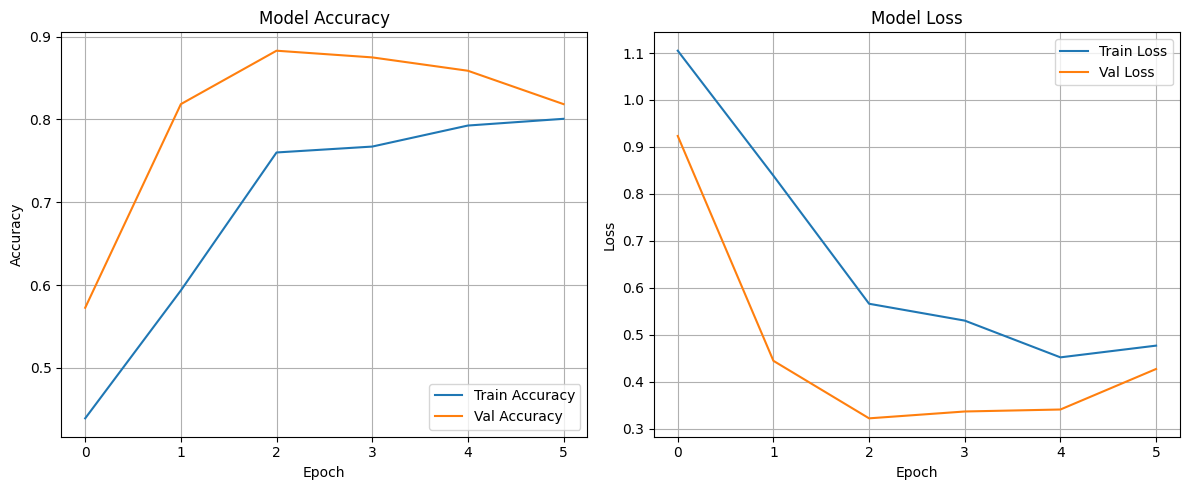

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


In [ ]:
import matplotlib.pyplot as plt

# 정확도 그래프
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 손실 그래프
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
print(history.history.keys())

In [ ]:
import tensorflow as tf

# 모델 경로 (.h5)
model_path = '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/오이/딥러닝 모델/cucumber_growth_model.h5'

# 저장할 TFLite 경로
tflite_path = '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/오이/딥러닝 모델/cucumber_growth_model.tflite'

# 모델 불러오기
model = tf.keras.models.load_model(model_path)

# TFLite 변환기 생성
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# 최적화 옵션 (선택사항)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# 변환 수행
tflite_model = converter.convert()

# TFLite 모델 저장
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

print("✅ 변환 완료! TFLite 파일이 저장되었습니다.")


Saved artifact at '/tmp/tmpixh_4w7w'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  137483588930064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137483588932752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137483588934480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137483588932176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137483588937936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137483588938704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137483588938128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137483588937168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137483588939856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137483588940816: TensorSpec(shape=(), dtype=tf.resource, name=None)
✅ 변환 완료! TFLite

In [ ]:
import tensorflow as tf
import os

# 3. .h5 모델 경로 설정 (사용자 맞춤 경로로 바꾸세요)
h5_model_path = '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/오이/딥러닝 모델/cucumber_growth_model.h5'

# 4. 모델 불러오기
model = tf.keras.models.load_model(h5_model_path)

# 5. SavedModel 형식으로 저장 (tflite 변환을 위해)
saved_model_dir = '/content/saved_model'
model.export(saved_model_dir)

# 6. TFLite 변환: 연산자 버전 낮추기 (기본 연산만 사용)
converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]  # 고버전 연산 방지
# converter.optimizations = [tf.lite.Optimize.DEFAULT]  # (선택) 양자화 시 사용

tflite_model = converter.convert()

# 7. Google Drive에 저장할 경로 설정
output_path = '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/오이/딥러닝 모델/cucumber_growth.tflite'

# 8. .tflite 파일로 저장
with open(output_path, 'wb') as f:
    f.write(tflite_model)

print("✅ 변환 완료! Google Drive에 저장되었습니다:", output_path)

Saved artifact at '/content/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  134748070807696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134748070811920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134748070812880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134748070808272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134748070816912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134748070817680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134748070817104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134748070816144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134748070818832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134748070819792: TensorSpec(shape=(), dtype=tf.resource, name=None)
✅ 변환 완료! Go